# Download the dataset and install packages

In [ ]:
# @title
# !pip install numpyro==0.10.0
# !pip install jax==0.4.2 jaxlib==0.4.2
# !pip install numpyro
# !pip install jax jaxlib
# !pip install -q git+https://github.com/ziatdinovmax/gpax.git

!pip install gdown==4.6.0
!pip install spgl1
!pip install hoffmanstmpy
# !gdown 1vrNcCfdDSamWV4e0GPExIH1xJak_xViT
# !gdown 1h99NuYxeFv52A_-zIwCDh2msJQuU7lRa

# SmB6 + URS topological Kondo insulator dataset
!gdown --folder https://drive.google.com/drive/folders/1LlX1jRJ8c76nfj1PlCAOLLpu4xpf6KCp?usp=share_link

Retrieving folder list
Processing file 1kiyd-Wmi2LVeOdgViMefL4e8nBDoQJXN 2013-05-18_T20B-1_Grid Spectroscopy001.spy
Processing file 15qfPNdrdIIUJDSEzzvFCI_hWT6fmf0NL 2017-10-04_Fe_SmB6_002.spy
Processing file 1Q6juhNV64bgnF9vvhjLWPXQLbEs7duys 2017-11-23_Fe-SmB6_001.spy
Processing file 1tqIhx0jA13e0Gr9WSOJjK7P_la6PTrnv URS.spy
Retrieving folder list completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1kiyd-Wmi2LVeOdgViMefL4e8nBDoQJXN
To: /content/SmB6 datasets/2013-05-18_T20B-1_Grid Spectroscopy001.spy
100% 48.1M/48.1M [00:00<00:00, 76.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=15qfPNdrdIIUJDSEzzvFCI_hWT6fmf0NL
To: /content/SmB6 datasets/2017-10-04_Fe_SmB6_002.spy
100% 16.2M/16.2M [00:00<00:00, 81.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Q6juhNV64bgnF9vvhjLWPXQLbEs7duys
To: /content/SmB6 datasets/2017-11-23_Fe-SmB6_001.spy
100% 146M/146M [00:01<00:00, 141MB/s]
Downloading...


In [39]:
# @title
import stmpy
import stmpy.tools as st
import stmpy.driftcorr as dfc
import h5py
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import gdown

from spgl1 import spgl1, spg_lasso, spg_bp, spg_bpdn, spg_mmv
from scipy.sparse.linalg import LinearOperator

In [40]:
# @title
# Define the 2D ss + FT operator

class partialFourier(LinearOperator):
    def __init__(self, idx, n):
        self.idx = idx
        self.n = n
        self.shape = (len(idx), n)
        self.dtype = np.complex128
    def _matvec(self, x):
        # % y = P(idx) * FFT(x)
        z = np.fft.fft(x) / np.sqrt(self.n)
        return z[self.idx]
    def _rmatvec(self, x):
        z = np.zeros(self.n,dtype=complex)
        z[self.idx] = x
        return np.fft.ifft(z) * np.sqrt(self.n)


def get_opa(n, ri):
  '''

  '''
  return partialFourier(idx=ri, n=n)


In [41]:
# @title
# Pre-define functions for invFT

def invFT_filter(A, bp, width=2, lattice=False):
    if len(np.shape(A)) == 2:
        g = 0
        x = np.arange(np.shape(A)[-1])
        for i in range(len(bp)):
            x0, y0 = bp[i] # coordinates of the Bragg peak
            g = g + st.gauss2d(x, x, p=[x0, y0, width, width, 1, 0])
        mask = g if lattice else 1-g
        A_ft_masked = st.fft(A, output='complex') * mask
        A_masked = np.real(st.ifft(A_ft_masked))
    else:
        A_masked = np.zeros_like(A)
        g = 0
        x = np.arange(np.shape(A)[-1])
        for i in range(len(bp)):
            x0, y0 = bp[i] # coordinates of the Bragg peak
            g = g + st.gauss2d(x, x, p=[x0, y0, width, width, 1, 0])
        mask = g if lattice else 1-g

        for i in range(len(A)):
            temp = st.fft(A[i], output='complex') * mask
            A_masked[i] = np.real(st.ifft(temp))
    return A_masked


In [42]:
def convert_ri(index, nx, ny, d=2):
  if d == 2:
    x0, y0 = index
    out = int((x0 - 1) * nx + y0 - 1)
    return out
  else:
    x0 = index // nx
    y0 = index % ny
    return [x0, y0]

# Load the data

In [5]:
# # home = '/content/drive/MyDrive/Datasets/DKL-STM/'
# home = 'SmB6 datasets'

# fnames = ['2013-05-18_T20B-1_Grid Spectroscopy001.spy',
#  '2017-10-04_Fe_SmB6_002.spy',
#  '2017-11-23_Fe-SmB6_001.spy',
#  'URS.spy']

# data = []

# for ix in fnames:
#   data.append(stmpy.load(home+"/{}".format(ix)))

In [ ]:
!gdown 1vrNcCfdDSamWV4e0GPExIH1xJak_xViT
!gdown 1h99NuYxeFv52A_-zIwCDh2msJQuU7lRa
!ls

zsh:1: command not found: gdown
zsh:1: command not found: gdown
40 nm liy at -22 mV.png
40 nm liy GT at -22 mV.png
40 nm rec bp at -22 mV.png
40 nm rec bpdn at -22 mV.png
40 nm topo.png
Adaptive_sparse_sampling.ipynb
Best maps on BSCCO.ipynb
example.pdf
ft 40 nm liy at -22 mV.png
ft 40 nm liy GT at -22 mV.png
ft 40 nm rec bp at -22 mV.png
ft 40 nm rec bpdn at -22 mV.png
ft 40 nm topo.png
LIY at -22 mv with 0.14 nS span.png
Sparse_sampling_figure_plot_for_40_nm_map.ipynb
Sparse_sampling_figure_plot.ipynb


In [2]:
!gdown --folder "https://drive.google.com/drive/folders/1LlX1jRJ8c76nfj1PlCAOLLpu4xpf6KCp?usp=share_link" -O ../data/

Retrieving folder list
Processing file 1kiyd-Wmi2LVeOdgViMefL4e8nBDoQJXN 2013-05-18_T20B-1_Grid Spectroscopy001.spy
Processing file 15qfPNdrdIIUJDSEzzvFCI_hWT6fmf0NL 2017-10-04_Fe_SmB6_002.spy
Processing file 1Q6juhNV64bgnF9vvhjLWPXQLbEs7duys 2017-11-23_Fe-SmB6_001.spy
Processing file 1tqIhx0jA13e0Gr9WSOJjK7P_la6PTrnv URS.spy
Retrieving folder list completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1kiyd-Wmi2LVeOdgViMefL4e8nBDoQJXN
To: /Users/marcosjohnsonnoya/Coding/SparseSampling/data/SmB6 datasets/2013-05-18_T20B-1_Grid Spectroscopy001.spy
100%|██████████████████████████████████████| 48.1M/48.1M [00:01<00:00, 39.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=15qfPNdrdIIUJDSEzzvFCI_hWT6fmf0NL
To: /Users/marcosjohnsonnoya/Coding/SparseSampling/data/SmB6 datasets/2017-10-04_Fe_SmB6_002.spy
100%|██████████████████████████████████████| 16.2M/16.2M [00:00<00:00, 44.8MB/s]
Downloading...
From: https:

In [27]:
fnames = ['Grid Spectroscopy-BSCCO-2022-09-04-002.3ds',
 '2019-07-11-002 LIY local corr new.spy',
 'SmB6 datasets/2017-10-04_Fe_SmB6_002.spy',
 'SmB6 datasets/2017-11-23_Fe-SmB6_001.spy',
 'SmB6 datasets/URS.spy']

data = []

for ix in fnames:
  data.append(stmpy.load("../data/{}".format(ix), biasOffset=False))

File import successful.


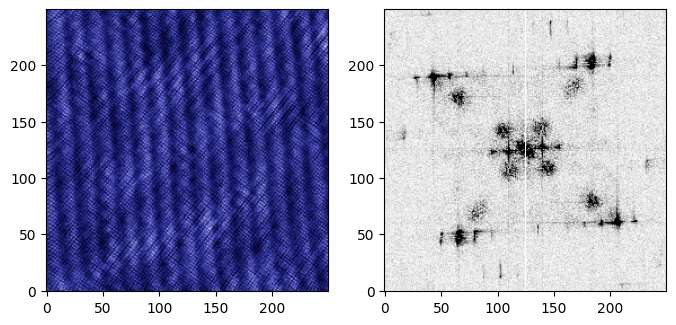

In [ ]:
d = data[0]
print(d)
z = stmpy.tools.lineSubtract(d.LIY[0], 1)
dfc.display(z)
# plt.imshow(np.mean(d.LIY, axis=0))

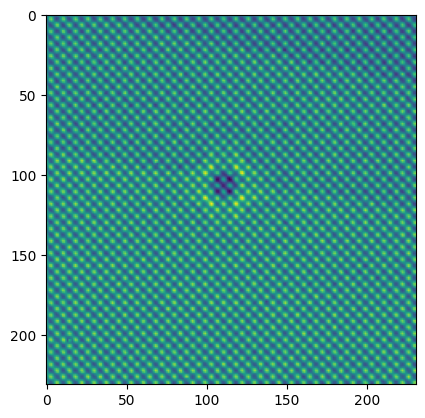

In [ ]:
d = data[1]
z = stmpy.tools.lineSubtract(d.liy[-1], 1)
plt.imshow(z)
plt.imshow(np.mean(d.liy, axis=0))

# Adaptive sparse sampling simulation

## Normal sparse sampling of 10%

In [ ]:
index = len(d.en) // 2
z_test = d.LIY[index] / np.mean(d.LIY[index]) # normalized full grid map

nx, ny = np.shape(z_test)
k = round(nx * ny * 0.1) # 20% sample
ri1 = np.random.choice(nx * ny, k, replace=False) # random sample of indices

dfc.display(z_test)

AttributeError: 'Spy' object has no attribute 'liy'

In [11]:
# sparse sampled map
z_ss = z_test.flat[ri1]

In [12]:
# Generate the ss + invFT operator
opA = get_opa(n=nx * ny, ri=ri1)

In [13]:
# Reconstruct the simulated ss map with BPDN method

# Sovle the L1 norm optimization problem with the spgl1.spg_bp method
sigma = 1e-2 #     % Desired ||Ax - b||_2
x,resid,grad,info = spg_bpdn(opA, z_ss, sigma=sigma, iter_lim=1e5, verbosity=2e-3)

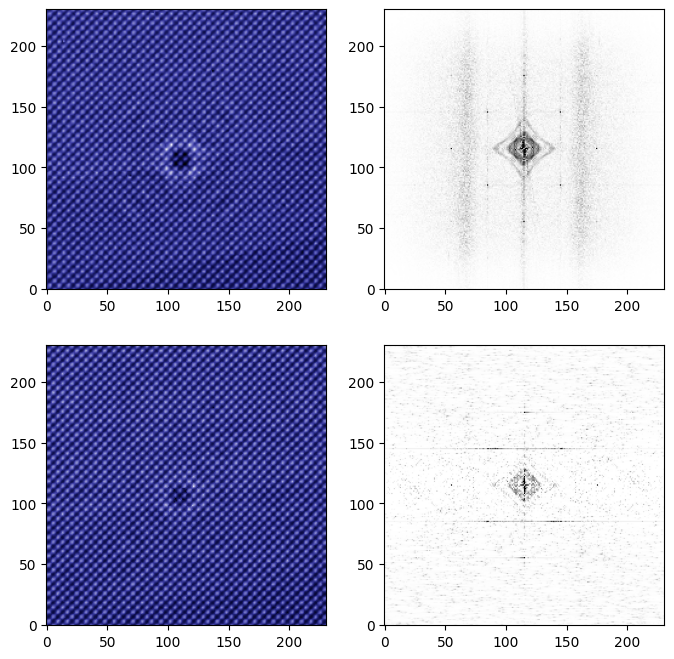

In [14]:
# We need to transfer the z back to the real space
z_rec1 = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]
dfc.display(z_test, z_rec1*np.mean(z_test)/np.mean(z_rec1))

## Adaptive sparse sampling of 5% + 5 %

### 5% of even distribution of points

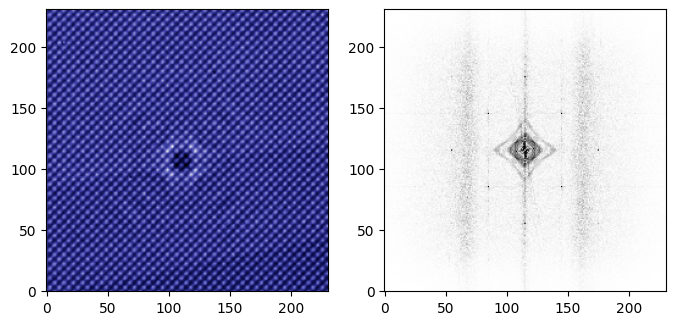

In [15]:
index = len(d.en) // 2
z_test = d.liy[index] / np.mean(d.liy[index]) # normalized full grid map

nx, ny = np.shape(z_test)
k1 = round(nx * ny * 0.05) # 20% sample
ri2_1 = np.random.choice(nx * ny, k1, replace=False) # random sample of indices

dfc.display(z_test)

### 5% of Gaussian distribution centered at impurities

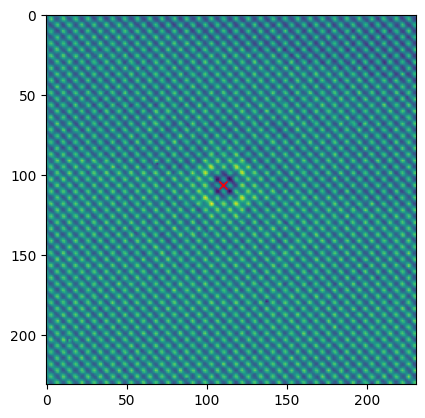

In [16]:
plt.imshow(z_test)
plt.plot(110, 106, 'rx')

In [17]:
def generate_unique_coordinates(mean, covariance_matrix, num_points):
    generated_coordinates = []

    while len(generated_coordinates) < num_points:
        # Generate a random coordinate
        random_coordinate = np.random.multivariate_normal(mean, covariance_matrix)

        # Round to the nearest integers
        rounded_coordinate = np.round(random_coordinate).astype(int)

        # Check if the coordinate is already in the list
        # if not any(np.array_equal(rounded_coordinate, coord) for coord in generated_coordinates):
        #     generated_coordinates.append(rounded_coordinate)
        generated_coordinates.append(rounded_coordinate)

    return np.unique(np.array(generated_coordinates), axis=0)

def convert_ri(index, nx, ny, d=2):
  if d == 2:
    x0, y0 = index
    out = int((x0 - 1) * nx + y0 - 1)
    return out
  else:
    x0 = index // nx
    y0 = index % ny
    return [x0, y0]

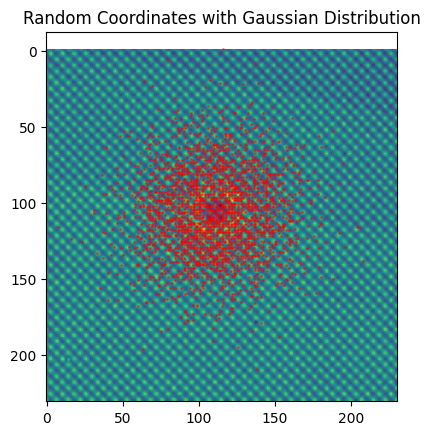

In [18]:
k2 = round(nx * ny * 0.06) # 20% sample

# Parameters
x0, y0 = 110, 106  # Center of the Gaussian distribution
num_points = k2  # Number of random points to generate

# Covariance matrix (controls the spread of points)
covariance_matrix = np.array([[750.0, 0],
                              [0, 750.0]])

# Generate random coordinates
ri2_2 = generate_unique_coordinates([x0, y0], covariance_matrix, num_points)

# Plot the generated points
plt.imshow(z_test)
plt.scatter(ri2_2[:, 0], ri2_2[:, 1], s=1, c='r', alpha=0.5)
plt.title('Random Coordinates with Gaussian Distribution')
# plt.xlabel('X-axis')
# plt.ylabel('Y-axis')
plt.show()

In [19]:
ri2_temp = []

for i in range(len(ri2_2)):
  temp = convert_ri(ri2_2[i], nx=nx, ny=ny)
  if temp <= nx * ny:
    ri2_temp.append(temp)

ri2_temp = np.array(ri2_temp)

In [20]:
len(ri2_1), len(ri2_temp)

(2668, 2714)

In [21]:
ri2 = np.concatenate((ri2_1, ri2_temp))
len(ri2)

5382

In [22]:
# sparse sampled map
z_ss = z_test.flat[ri2]

In [23]:
# Generate the ss + invFT operator
opA = get_opa(n=nx * ny, ri=ri2)

In [24]:
# Reconstruct the simulated ss map with BPDN method

# Sovle the L1 norm optimization problem with the spgl1.spg_bp method
sigma = 1e-2 #     % Desired ||Ax - b||_2
x,resid,grad,info = spg_bpdn(opA, z_ss, sigma=sigma, iter_lim=1e5, verbosity=2e-3)

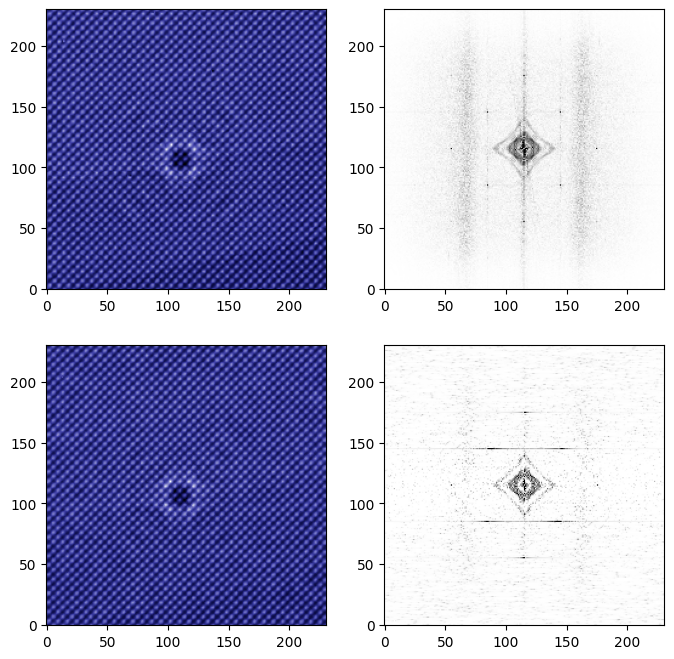

In [25]:
# We need to transfer the z back to the real space
z_rec2 = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]
dfc.display(z_test, z_rec2*np.mean(z_test)/np.mean(z_rec2))

### Compare the two results

In [26]:
# Convert the ri1 and ri2 to 2D

ri1_2d = []
ri2_2d = []

for i in range(len(ri1)):
  coord = convert_ri(ri1[i], nx=nx, ny=ny, d=1)
  ri1_2d.append(coord)

ri1_2d = np.array(ri1_2d)

for i in range(len(ri2)):
  coord = convert_ri(ri2[i], nx=nx, ny=ny, d=1)
  ri2_2d.append(coord)

ri2_2d = np.array(ri2_2d)

5336 5382


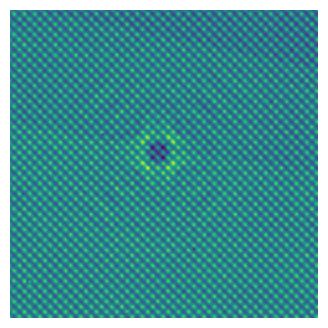

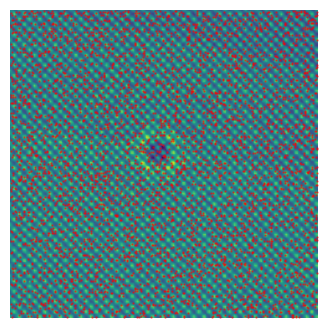

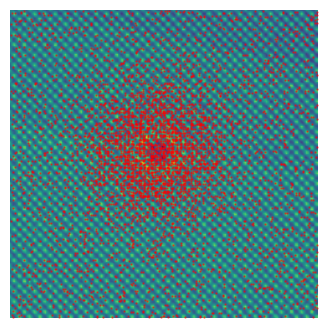

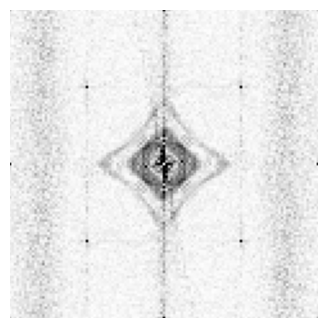

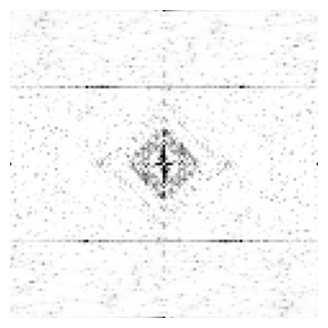

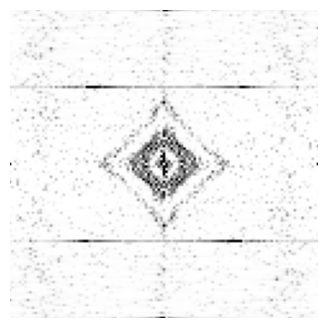

In [27]:
import os

fig, ax = plt.subplots(figsize=[4,4])
ax.imshow(z_test, rasterized=True)
ax.axis('off')
plt.savefig(os.path.expanduser("~/Desktop/fig1/full_grid.pdf"), bbox_inches='tight')

fig, ax = plt.subplots(figsize=[4,4])
ax.imshow(z_test, rasterized=True)
sc = ax.scatter(ri1_2d[:, 0], ri1_2d[:, 1], s=0.5, c='r', alpha=0.5)
sc.set_rasterized(True)
ax.axis('off')
plt.savefig(os.path.expanduser("~/Desktop/fig1/10pct_even_sampling.pdf"), bbox_inches='tight')

fig, ax = plt.subplots(figsize=[4,4])
ax.imshow(z_test, rasterized=True)
sc = ax.scatter(ri2_2d[:, 0], ri2_2d[:, 1], s=0.5, c='r', alpha=0.5)
sc.set_rasterized(True)
ax.axis('off')
plt.savefig(os.path.expanduser("~/Desktop/fig1/5pct_even_5pct_adaptive_sampling.pdf"), bbox_inches='tight')

ft1 = stmpy.tools.fft(z_test, zeroDC=True)
c1 = np.mean(ft1)
s1 = np.std(ft1)

ft2 = stmpy.tools.fft(z_rec1, zeroDC=True)
c2 = np.mean(ft2)
s2 = np.std(ft2)

ft3 = stmpy.tools.fft(z_rec2, zeroDC=True)
c3 = np.mean(ft3)
s3 = np.std(ft3)

center = nx // 2

fig, ax = plt.subplots(figsize=[4,4])
ax.imshow(ft1, cmap=stmpy.cm.gray_r, clim=[0, c1+3*s1], rasterized=True)
ax.set_xlim(center-60, center+60)
ax.set_ylim(center-60, center+60)
ax.axis('off')
plt.savefig(os.path.expanduser("~/Desktop/fig1/ft_full_grid.pdf"), bbox_inches='tight')

fig, ax = plt.subplots(figsize=[4,4])
ax.imshow(ft2, cmap=stmpy.cm.gray_r, clim=[0, c2+3*s2], rasterized=True)
ax.set_xlim(center-60, center+60)
ax.set_ylim(center-60, center+60)
ax.axis('off')
plt.savefig(os.path.expanduser("~/Desktop/fig1/ft_10pct_even_sampling.pdf"), bbox_inches='tight')

fig, ax = plt.subplots(figsize=[4,4])
ax.imshow(ft3, cmap=stmpy.cm.gray_r, clim=[0, c3+3*s3], rasterized=True)
ax.set_xlim(center-60, center+60)
ax.set_ylim(center-60, center+60)
ax.axis('off')
plt.savefig(os.path.expanduser("~/Desktop/fig1/ft_5pct_even_5pct_adaptive_sampling.pdf"), bbox_inches='tight')

print(len(ri1), len(ri2))

# invFT to determine the sampling mask

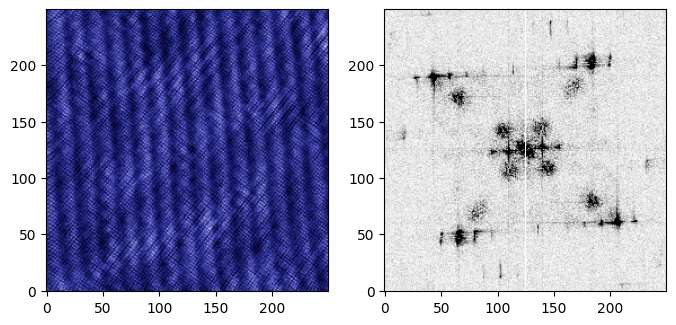

In [9]:
d = data[0]
z = stmpy.tools.lineSubtract(d.LIY[0], 1)
dfc.display(z)
# plt.imshow(np.mean(d.LIY, axis=0))

## Normal sparse sampling of 10 %

In [11]:
# Generate the random indices

z_test = d.LIY[-1] / np.mean(d.LIY[-1]) # normalized full grid map

nx, ny = np.shape(z_test)
# k = 0.25
k = round(nx * ny * 0.1) # 20% sample
ri1 = np.random.choice(nx * ny, k, replace=False) # random sample of indices
# savetxt('100x100 mask.txt', ri)
# ri = loadtxt('100x100 mask.txt')

In [12]:
# sparse sampled map
z_ss = z_test.flat[ri1]

# Generate the ss + invFT operator
opA = get_opa(n=nx * ny, ri=ri1)

In [13]:
# Reconstruct the simulated ss map with BPDN method

# Sovle the L1 norm optimization problem with the spgl1.spg_bp method
sigma = 1e-2 #     % Desired ||Ax - b||_2
x,resid,grad,info = spg_bpdn(opA, z_ss, sigma=sigma, iter_lim=1e5, verbosity=2e-3)

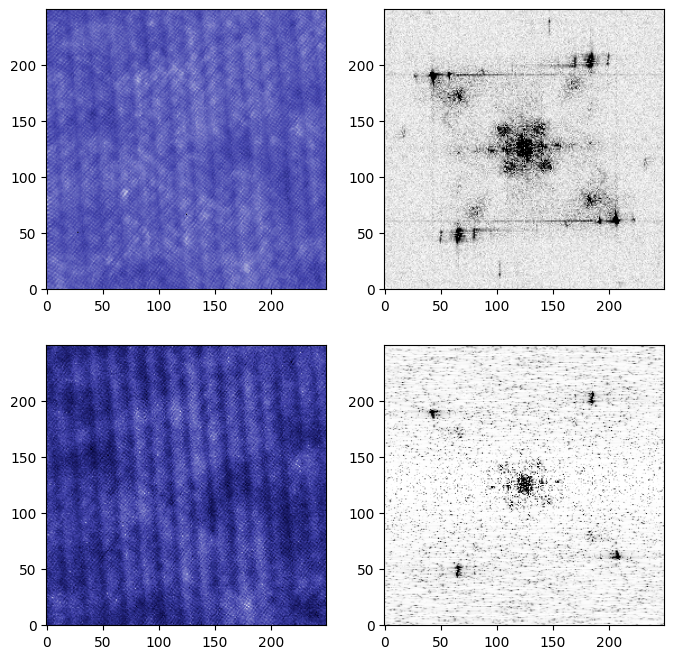

In [14]:
# We need to transfer the z back to the real space
z_rec1 = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]
dfc.display(z_test, z_rec1*np.mean(z_test)/np.mean(z_rec1))

## 5% + 5%

### invFT to find the distribution of QPI of interest

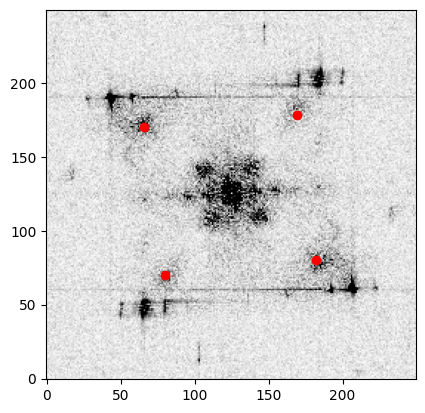

In [16]:
z_ft = st.fft(z_test, zeroDC=True)

c = np.mean(z_ft)
s = np.std(z_ft)

plt.imshow(z_ft, origin='lower', cmap=stmpy.cm.gray_r, clim=[0, c+3*s])
plt.plot(66, 170, 'ro')
plt.plot(169, 178, 'ro')
plt.plot(80, 70, 'ro')
plt.plot(182, 80, 'ro')

masks = np.array([
    [66, 170] ,
    [169, 178],
    [80, 70]  ,
    [182, 80] ,
])

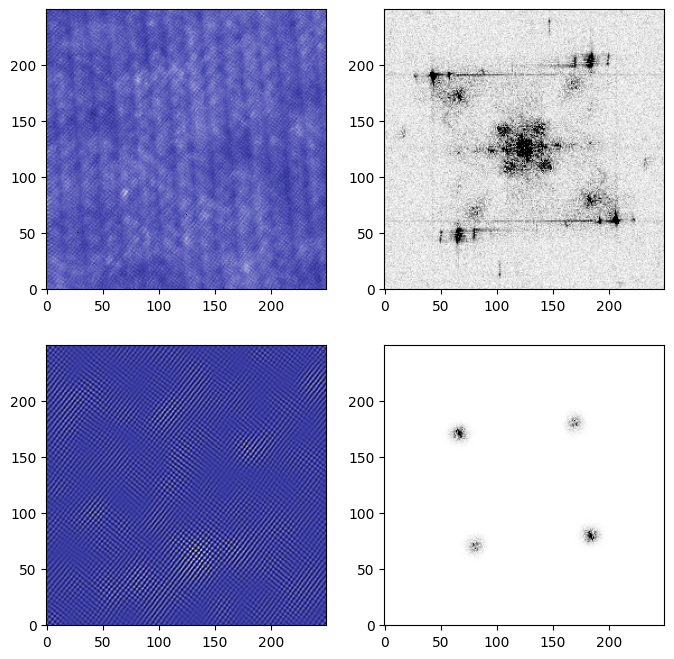

In [17]:
# invFT filtering the Bragg peaks in the topo

z_masked = invFT_filter(z_test, bp=masks, width=5, lattice=True)

dfc.display(z_test, z_masked)

array([0.06197774, 0.04610709, 0.04413774, 0.04371133, 0.04238035,
       0.03871685, 0.03810165, 0.03781952, 0.03627723, 0.03583512,
       0.03348495, 0.03191732, 0.03116326, 0.03100282, 0.03083747,
       0.03000724, 0.03000432, 0.02973622, 0.0292192 ])

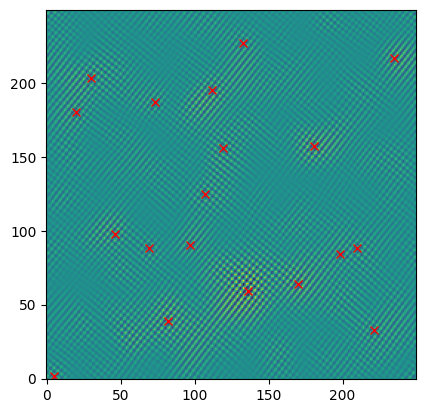

In [18]:
coords = st.find_extrema(z_masked, n=(19,0))

plt.imshow(z_masked, origin='lower')
plt.plot(coords[:,1], coords[:,0], 'rx')
g_intensity = np.zeros(len(coords))
for i in range(len(coords)):
  x, y = coords[i]
  g_intensity[i] = z_masked[int(x),int(y)]
g_intensity

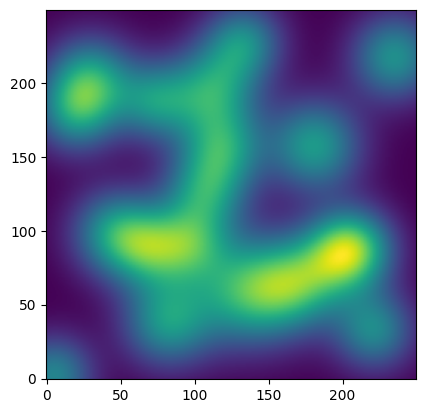

In [19]:
intensity = (g_intensity - z_masked.min()) / (z_masked.max() - z_masked.min())

r = 25 * intensity

x = np.arange(nx)

mask = 0

for i in range(len(coords)):
  mask += st.gauss2d(x, x, p=[coords[i,1], coords[i, 0], r[i], r[i], intensity[i], intensity[i]])
  # mask += st.gauss2d(x, x, p=[coords[i,1], coords[i, 0], 15, 15, 1, 1])
mask /= np.max(mask)
plt.imshow(mask, origin='lower')

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Define a 2D custom density function
def custom_density(x, y):
    # Example: Gaussian distribution centered at (0, 0)
    return np.exp(-0.5 * (x**2 + y**2)) / (2 * np.pi)

# Generate random integer coordinates with the given 2D density
def generate_random_coordinates(num_points, nx, mask):
    generated_coordinates = []

    while len(generated_coordinates) < num_points:
        # Generate random coordinates from a uniform distribution
        x, y = np.random.randint(0, nx, size=2)

        # Generate a random number from a uniform distribution
        u = np.random.rand()

        # Evaluate the density function at the generated coordinates
        density_value = mask[x, y]

        # Accept the coordinates with a probability proportional to the density value
        if u < density_value:
            generated_coordinates.append([x, y])

    return np.array(generated_coordinates)

# # Number of random points
# num_points = 100

# # Generate random integer coordinates with the given 2D density function
# random_coordinates = generate_random_coordinates(num_points, custom_density)

# # Plot the generated points
# plt.scatter(random_coordinates[:, 0], random_coordinates[:, 1], alpha=0.5)
# plt.title('Random Integer Coordinates with Custom 2D Density Function')
# plt.xlabel('X-axis')
# plt.ylabel('Y-axis')
# plt.show()


### 5% of even distribuction

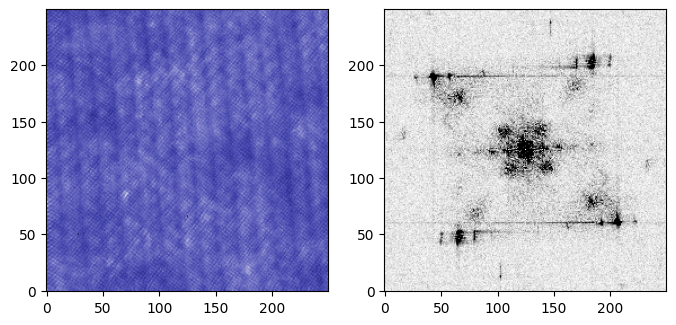

In [21]:
nx, ny = np.shape(z_test)
k1 = round(nx * ny * 0.05) # 20% sample
ri2_1 = np.random.choice(nx * ny, k1, replace=False) # random sample of indices

dfc.display(z_test)

### 5% of adaptive distribution

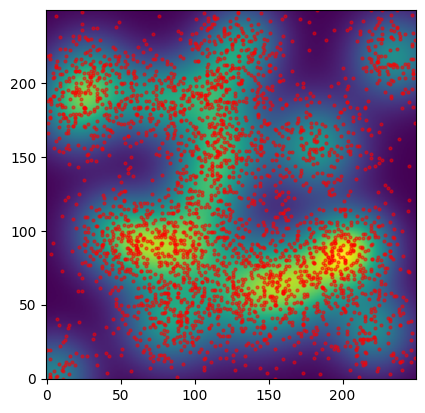

In [22]:
# Number of random points
k2 = round(nx * ny * 0.05) # 20% sample
# z_mask_filter = st.nsigma_local(z_masked)
# mask = (z_mask_filter - z_mask_filter.min())/z_mask_filter.ptp()

# Generate random integer coordinates with the given 2D density function
random_coordinates = generate_random_coordinates(k2, nx=nx, mask=mask)

# Plot the generated points
plt.imshow(mask, origin='lower')
plt.scatter(random_coordinates[:, 1], random_coordinates[:, 0], s=4, c='r', alpha=0.5)
plt.show()

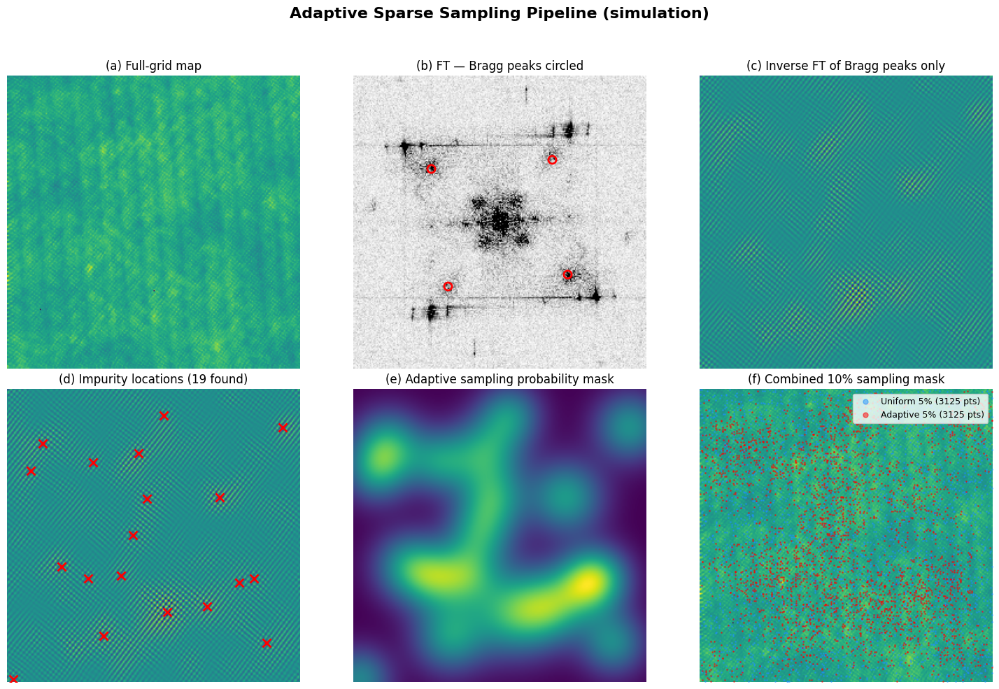

In [52]:
# --- Summary figure: ASS pipeline walkthrough ---
# NOTE: This is a simulation — using dI/dV (z_test) in place of topography.
# In a real experiment, the simultaneously acquired topo would be used.
# Assumes z_test, masks, z_masked, coords, g_intensity, mask,
# random_coordinates, nx, ny are already computed from cells above.

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# (a) Full-grid map (simulating topo)
axes[0, 0].imshow(z_test, origin='lower', rasterized=True)
axes[0, 0].set_title('(a) Full-grid map', fontsize=12)
axes[0, 0].axis('off')

# (b) FT with Bragg peaks marked
z_ft_disp = st.fft(z_test, zeroDC=True)
c, s = np.mean(z_ft_disp), np.std(z_ft_disp)
axes[0, 1].imshow(z_ft_disp, origin='lower', cmap=stmpy.cm.gray_r, clim=[0, c + 3*s], rasterized=True)
for bp in masks:
    axes[0, 1].plot(bp[0], bp[1], 'ro', markersize=8, markerfacecolor='none', markeredgewidth=2)
axes[0, 1].set_title('(b) FT \u2014 Bragg peaks circled', fontsize=12)
axes[0, 1].axis('off')

# (c) Fourier-filtered real-space map (lattice-only)
axes[0, 2].imshow(z_masked, origin='lower', rasterized=True)
axes[0, 2].set_title('(c) Inverse FT of Bragg peaks only', fontsize=12)
axes[0, 2].axis('off')

# (d) Filtered map with impurity locations marked
axes[1, 0].imshow(z_masked, origin='lower', rasterized=True)
axes[1, 0].plot(coords[:, 1], coords[:, 0], 'rx', markersize=8, markeredgewidth=2)
axes[1, 0].set_title(f'(d) Impurity locations ({len(coords)} found)', fontsize=12)
axes[1, 0].axis('off')

# (e) Gaussian probability mask
axes[1, 1].imshow(mask, origin='lower', rasterized=True)
axes[1, 1].set_title('(e) Adaptive sampling probability mask', fontsize=12)
axes[1, 1].axis('off')

# (f) Adaptive + uniform sample points overlaid on map
k_uniform = round(nx * ny * 0.05)
k_adaptive = round(nx * ny * 0.05)
ri_uniform = np.random.choice(nx * ny, k_uniform, replace=False)
ri_uniform_2d = np.column_stack([ri_uniform % ny, ri_uniform // ny])
adaptive_pts = generate_random_coordinates(k_adaptive, nx=nx, mask=mask)
axes[1, 2].imshow(z_test, origin='lower', rasterized=True)
sc1 = axes[1, 2].scatter(ri_uniform_2d[:, 0], ri_uniform_2d[:, 1],
                   s=1, c='dodgerblue', alpha=0.5, label=f'Uniform 5% ({k_uniform} pts)', rasterized=True)
sc2 = axes[1, 2].scatter(adaptive_pts[:, 1], adaptive_pts[:, 0],
                   s=1, c='red', alpha=0.5, label=f'Adaptive 5% ({k_adaptive} pts)', rasterized=True)
axes[1, 2].legend(loc='upper right', fontsize=9, markerscale=5)
axes[1, 2].set_title('(f) Combined 10% sampling mask', fontsize=12)
axes[1, 2].axis('off')

fig.suptitle('Adaptive Sparse Sampling Pipeline (simulation)',
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/figure_ASS_pipeline.pdf', bbox_inches='tight', dpi=300)
plt.show()


In [45]:
ri2_temp = []

for i in range(len(random_coordinates)):
  temp = convert_ri(random_coordinates[i], nx=nx, ny=ny)
  if temp <= nx * ny:
    ri2_temp.append(temp)

ri2_temp = np.array(ri2_temp)

In [46]:
len(ri2_1), len(ri2_temp)

(3125, 3125)

In [47]:
ri2 = np.concatenate((ri2_1, ri2_temp))
len(ri2)

6250

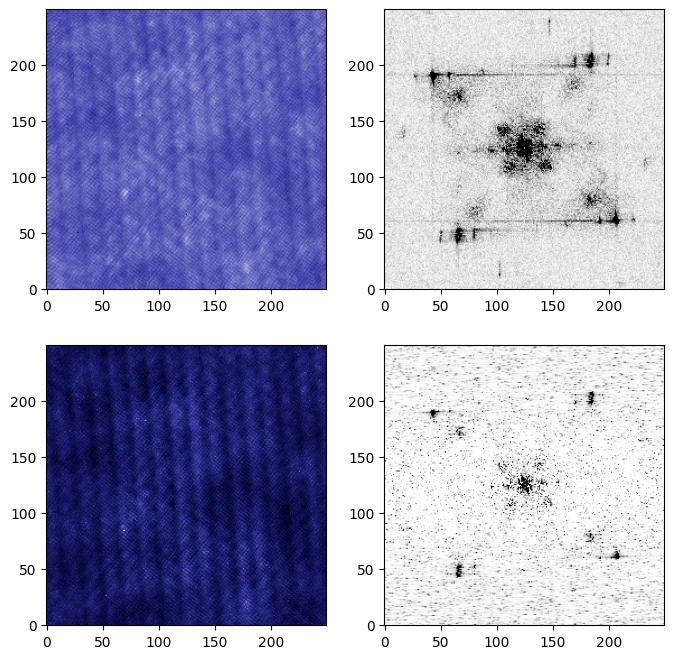

In [48]:
# sparse sampled map
z_ss = z_test.flat[ri2]

# Generate the ss + invFT operator
opA = get_opa(n=nx * ny, ri=ri2)

# Reconstruct the simulated ss map with BPDN method

# Sovle the L1 norm optimization problem with the spgl1.spg_bp method
sigma = 1e-2 #     % Desired ||Ax - b||_2
x,resid,grad,info = spg_bpdn(opA, z_ss, sigma=sigma, iter_lim=1e5, verbosity=2e-3)

# We need to transfer the z back to the real space
z_rec2 = np.real(np.fft.ifft(x).reshape(nx, ny))[::-1,::-1]
dfc.display(z_test, z_rec2*np.mean(z_test)/np.mean(z_rec2))

### Compare the two results

In [49]:
# Convert the ri1 and ri2 to 2D

ri1_2d = []
ri2_2d = []

for i in range(len(ri1)):
  coord = convert_ri(ri1[i], nx=nx, ny=ny, d=1)
  ri1_2d.append(coord)

ri1_2d = np.array(ri1_2d)

for i in range(len(ri2)):
  coord = convert_ri(ri2[i], nx=nx, ny=ny, d=1)
  ri2_2d.append(coord)

ri2_2d = np.array(ri2_2d)

6250 6250


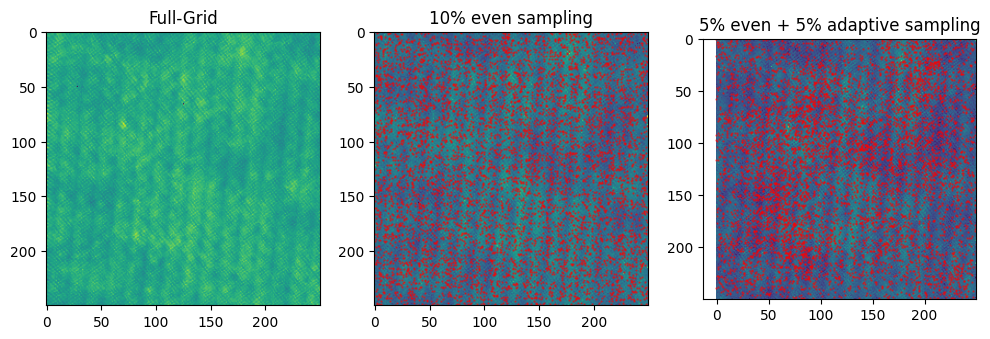

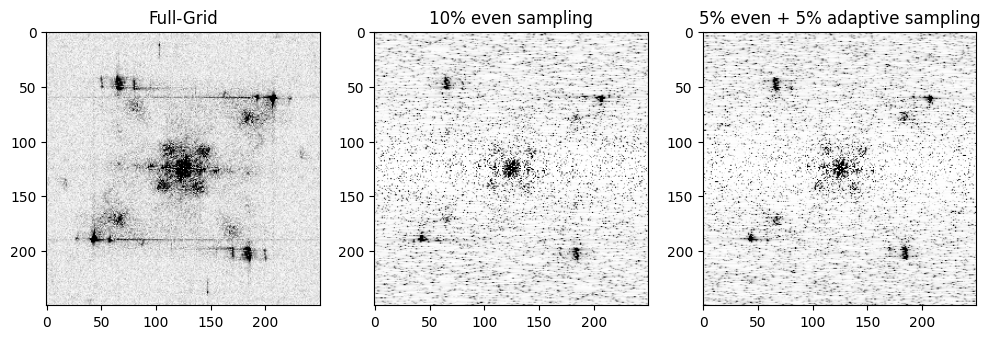

In [50]:
fig,ax=plt.subplots(1,3,figsize=[12,4])
ax[0].imshow(z_test)
ax[1].imshow(z_rec1)
ax[1].scatter(ri1_2d[:, 0], ri1_2d[:, 1], s=0.5, c='r', alpha=0.5)
ax[2].imshow(z_rec2)
ax[2].scatter(ri2_2d[:, 0], ri2_2d[:, 1], s=0.5, c='r', alpha=0.5)

titles = ['Full-Grid', '10% even sampling', '5% even + 5% adaptive sampling']
for i, axis in enumerate(ax):
  axis.set_title(titles[i])

ft1 = stmpy.tools.fft(z_test, zeroDC=True)
c1 = np.mean(ft1)
s1 = np.std(ft1)

ft2 = stmpy.tools.fft(z_rec1, zeroDC=True)
c2 = np.mean(ft2)
s2 = np.std(ft2)

ft3 = stmpy.tools.fft(z_rec2, zeroDC=True)
c3 = np.mean(ft3)
s3 = np.std(ft3)

fig,ax=plt.subplots(1,3,figsize=[12,4])
ax[0].imshow(ft1, cmap=stmpy.cm.gray_r, clim=[0, c1+3*s1])
ax[1].imshow(ft2, cmap=stmpy.cm.gray_r, clim=[0, c2+3*s2])
ax[2].imshow(ft3, cmap=stmpy.cm.gray_r, clim=[0, c3+3*s3])

center = nx // 2

# titles = ['Full-Grid', '10% even sampling', '5% even + 5% adaptive sampling']
for i, axis in enumerate(ax):
  axis.set_title(titles[i])
  # axis.set_xlim(center-60, center+60)
  # axis.set_ylim(center-60, center+60)
print(len(ri1), len(ri2))